<a href="https://colab.research.google.com/github/cbishop4/MSE7530/blob/main/ClassNotebooks/F2026/20261111_EllipsometryRecording.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# MSE 7530 - Spectroscopic Ellipsometry, post-recording 11/11/2026
Almost all of the code contained in this walkthrough is from https://refellips.readthedocs.io/en/main/getting_started.html  
<font color='red'> Caution: the units in this code ($\mu m$ vs. $nm$ vs. $Å$) are inconsistent; the program mentions this, but it must be this way due to the conventions by which most instruments report data. Pay close attention to length units.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
! pip install refnx
! pip install refellips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 11.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 24.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [refnx]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for refellips: filename=refellips-0.0.6-py3-none-any.whl size=318159 sha256=fb3170421a99e4ac874c690a6b47d9aa1524134e660c9296917530faac957167
  Stored in directory: /root/.cache/pip/wheels/91/a1/7c/03363a9b6e4f79a8831033240fdf69d5a4197140ca12c810be
Successfully built refellips


In [ ]:
import sys
import os
from os.path import join as pjoin
import numpy as np
import matplotlib.pyplot as plt
import scipy

import refnx
from refnx.analysis import CurveFitter
from refnx.reflect import Slab

import refellips
from refellips.dataSE import DataSE, open_EP4file
from refellips.reflect_modelSE import ReflectModelSE
from refellips.objectiveSE import ObjectiveSE
from refellips.dispersion import RI, Cauchy, load_material

Loading the Github for this project - necessary to get the example files needed.

In [ ]:
! git clone https://github.com/refnx/refellips/

Cloning into 'refellips'...
remote: Enumerating objects: 1773, done.
remote: Counting objects: 100% (476/476), done.
remote: Compressing objects: 100% (174/174), done.
remote: Total 1773 (delta 330), reused 322 (delta 297), pack-reused 1297 (from 1)
Receiving objects: 100% (1773/1773), 4.20 MiB | 19.29 MiB/s, done.
Resolving deltas: 100% (1081/1081), done.


In [ ]:
pth = os.path.dirname(refellips.__file__)
dname = "/content/refellips/demos/testData1_11nm_PNIPAM_on_Si_EP4.dat"
file_path = pjoin(pth, "../", "demos", dname) # data from the software

<font size=5><font color='blue'>Goal: find the exact thickness of a film of PNIPAM on Silicon.

## Load the dataset

In [ ]:
data = DataSE(data=file_path)

In [ ]:
data

Data1D(data='/content/refellips/demos/testData1_11nm_PNIPAM_on_Si_EP4.dat', mask=None)

<font size=4> Let's examine our data.

In [ ]:
vars(data)

{'filename': '/content/refellips/demos/testData1_11nm_PNIPAM_on_Si_EP4.dat',
 'delimiter': '\t',
 'metadata': {},
 '_wavelength': array([658., 658., 658., 658.]),
 '_aoi': array([55., 60., 65., 70.]),
 '_psi': array([27.7 , 23.25, 17.8 , 11.7 ]),
 '_delta': array([170.2 , 166.35, 159.65, 143.9 ]),
 'weighted': False,
 'name': None,
 '_delta_flipped': False,
 'mask': array([ True,  True,  True,  True])}

Wavelength: 658 nm (visible light), all 4. Taken at 4 different angles of incidence. Wavelength and aoi are the collection parameters.  
Gives you psi and delta; psi is the ratio of amplitude of p- and s-polarized light. Delta is the phase shift between the p- and s-polarized.

Generally, when something has an underscore (_) in front of its variable, it means that the user typically shouldn't be accessing it (i.e, it's "under the hood" and exists primarily to be referenced by other functions). To be explicit about what we have here, though, let's plot the data:

Text(0.5, 0, 'Angle of Incidence (degrees)')

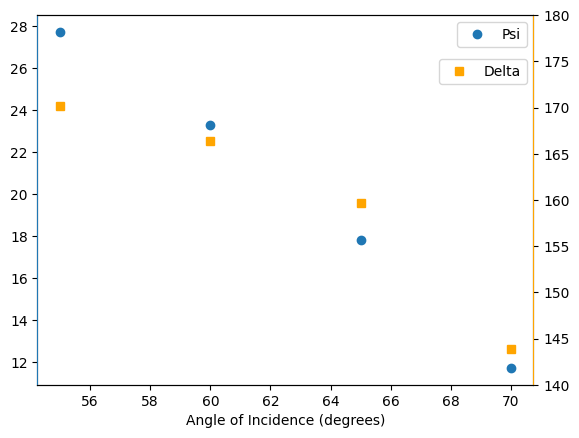

In [ ]:
fig, ax1 = plt.subplots()

ax2 = ax1.twinx() # making two y-axes
# blue data; first data plotted; psi on y-axis, a.o.i. on x-axis
ax1.plot(vars(data)['_aoi'],vars(data)['_psi'],'o',label='Psi')
# orange data; delta on y-axis, a.o.i. on x-axis (same 4 measurements as blue)
ax2.plot(vars(data)['_aoi'],vars(data)['_delta'],'s',color='orange',label='Delta')

# graph formatting
ax2.set_ylim(140,180)
ax1.legend(bbox_to_anchor=(1,1))
ax2.legend(bbox_to_anchor=(1,.9))
ax2.spines['left'].set_color('tab:blue')
ax2.spines['right'].set_color('orange')

ax1.set_xlabel('Angle of Incidence (degrees)')

## Set up all of the materials we will need.  
To model our PNIPAM film, we will need its Silicon substrate, a thermal SiO2 oxide that is found on silicon, PNIPAM optical constants, and air. They will be specified in different ways.

The first two are loaded with "load_material". They are specific materials that are already tabulated and exist within the refellips package.

In [ ]:
si = load_material("silicon") # well-computed optical constants
# specifying a variable name for any time we want silicon

In [ ]:
si # variable now specifies a set of refractive indices

In [ ]:
air = load_material("air") # same thing for air

In [ ]:
air

In [ ]:
vars(si)

{'name': '',
 'dispersive': True,
 'wavelength': 658,
 '_wav': array([206.6, 210.1, 213.8, 217.5, 221.4, 225.4, 229.6, 233.9, 238.4,
        243.1, 248. , 253. , 258.3, 263.8, 269.5, 275.5, 281.8, 288.3,
        295.2, 302.4, 310. , 317.9, 326.3, 335.1, 344.4, 354.2, 364.7,
        375.7, 387.5, 399.9, 413.3, 427.5, 442.8, 459.2, 476.9, 495.9,
        516.6, 539.1, 563.6, 590.4, 619.9, 652.5, 688.8, 729.3, 774.9,
        826.6]),
 '_RI': array([1.01 , 1.083, 1.133, 1.186, 1.247, 1.34 , 1.471, 1.579, 1.589,
        1.571, 1.57 , 1.597, 1.658, 1.764, 1.988, 2.452, 3.12 , 4.087,
        4.888, 5.02 , 5.01 , 5.016, 5.065, 5.156, 5.296, 5.61 , 6.522,
        6.709, 6.062, 5.57 , 5.222, 4.961, 4.753, 4.583, 4.442, 4.32 ,
        4.215, 4.123, 4.042, 3.969, 3.906, 3.847, 3.796, 3.752, 3.714,
        3.673]),
 '_EC': array([2.909e+00, 2.982e+00, 3.045e+00, 3.120e+00, 3.206e+00, 3.302e+00,
        3.366e+00, 3.353e+00, 3.354e+00, 3.429e+00, 3.565e+00, 3.749e+00,
        3.979e+00, 4.278e+00, 4.

Text(0.5, 0.98, 'Optical Constants for Silicon (refellips)')

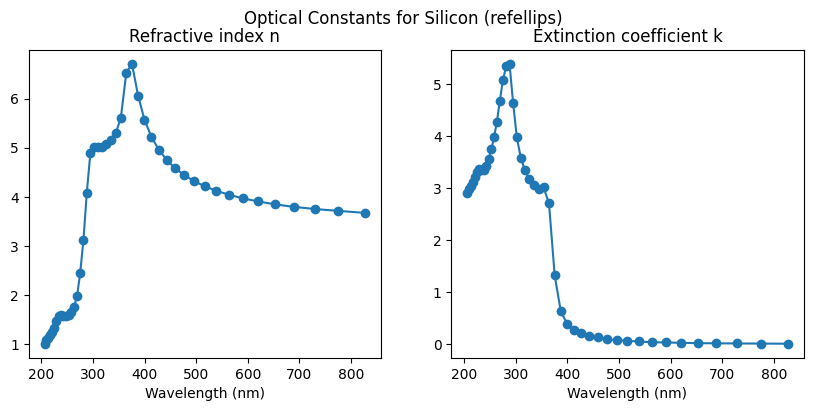

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].plot(vars(si)['_wav'], vars(si)['_RI'],'-o')
ax[1].plot(vars(si)['_wav'], vars(si)['_EC'],'-o')
ax[0].set_title('Refractive index n')
ax[1].set_title('Extinction coefficient k')

for a in ax:
  a.set_xlabel('Wavelength (nm)')

plt.suptitle('Optical Constants for Silicon (refellips)')

In [ ]:
vars(air)

{'name': '',
 'dispersive': True,
 'wavelength': 658,
 '_wav': array([ 230. ,  244.6,  259.2,  273.8,  288.4,  303. ,  317.6,  332.2,
         346.8,  361.4,  376. ,  390.6,  405.2,  419.8,  434.4,  449. ,
         463.6,  478.2,  492.8,  507.4,  522. ,  536.6,  551.2,  565.8,
         580.4,  595. ,  609.6,  624.2,  638.8,  653.4,  668. ,  682.6,
         697.2,  711.8,  726.4,  741. ,  755.6,  770.2,  784.8,  799.4,
         814. ,  828.6,  843.2,  857.8,  872.4,  887. ,  901.6,  916.2,
         930.8,  945.4,  960. ,  974.6,  989.2, 1004. , 1018. , 1033. ,
        1048. , 1062. , 1077. , 1091. , 1106. , 1121. , 1135. , 1150. ,
        1164. , 1179. , 1194. , 1208. , 1223. , 1237. , 1252. , 1267. ,
        1281. , 1296. , 1310. , 1325. , 1340. , 1354. , 1369. , 1383. ,
        1398. , 1413. , 1427. , 1442. , 1456. , 1471. , 1486. , 1500. ,
        1515. , 1529. , 1544. , 1559. , 1573. , 1588. , 1602. , 1617. ,
        1632. , 1646. , 1661. , 1675. , 1690. ]),
 '_RI': array([1.000308 

Text(0.5, 0.98, 'Optical Constants for Air (refellips)')

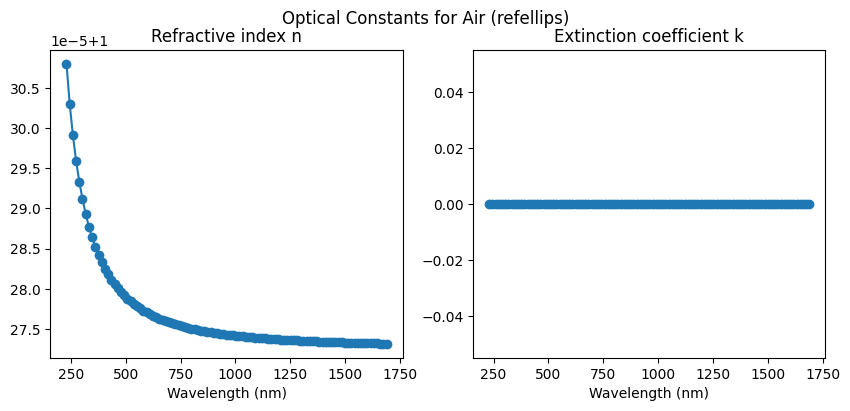

In [ ]:
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].plot(vars(air)['_wav'], vars(air)['_RI'],'-o')
ax[1].plot(vars(air)['_wav'], vars(air)['_EC'],'-o')
ax[0].set_title('Refractive index n')
ax[1].set_title('Extinction coefficient k')

for a in ax:
  a.set_xlabel('Wavelength (nm)')

plt.suptitle('Optical Constants for Air (refellips)')

Above is one way to specify refractive indices for a material; for well-known materials.

The next way to specify the refractive index is through the RI() method. Here, you will directly enter the optical constants for the material. Note that SiO2 optical constants are well-known and tabulated; we're doing it this way for sake of example.

In [ ]:
sio2 = RI([1.4563, 0]) # make a material like the ones above; but feed it our own info

In [ ]:
vars(sio2)

{'name': '',
 'dispersive': True,
 'wavelength': 658,
 '_wav': None,
 '_RI': 1.4563,
 '_EC': 0}

Finally (for this example), we can specify a material's optical constants by specifying what dispersion equation it follows. Here, we will do this for a Cauchy model, in which $k = 0$ and  
$n = A + \frac{B}{\lambda^{2}} + \frac{C}{\lambda^{4}} $,  
Where $\lambda$ must be in $\mu m$.

In [ ]:
PNIPAM = Cauchy(A=1.47, B=0.00495) # often, C is not used because it has such a small effect
# programming in a relationship between wavelength and RI n in this material

In [ ]:
vars(PNIPAM)

{'name': '',
 'dispersive': True,
 'wavelength': 658,
 'A': Parameter(value=1.47, name=' - cauchy A', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None),
 'B': Parameter(value=0.00495, name=' - cauchy B', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None),
 'C': Parameter(value=0.0, name=' - cauchy C', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None),
 '_parameters': Parameters(data=[Parameter(value=1.47, name=' - cauchy A', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), Parameter(value=0.00495, name=' - cauchy B', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), Parameter(value=0.0, name=' - cauchy C', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None)], name='')}

Because it is a continuous equation, we can compute the refractive index at any wavelength for this material. Let's, for example, plot it out for 200-850 nm (note that the Cauchy equation requires the wavelengths in microns):

Text(0, 0.5, 'n (unitless)')

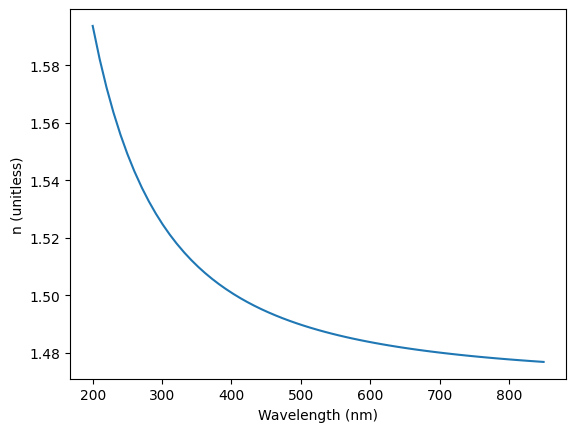

In [ ]:
wls = 10**-3*np.linspace(200, 850, num=(int((850-200)/10)),dtype=int) # make a range of wavelengths
def calcCauch(wl_um, A, B, C=0): # used a different name for the function because refellips already has something named "Cauchy"
  return A + B/(wl_um**2) + C/(wl_um**4) # calculates Cauchy relationship
plt.plot(wls*10**3,calcCauch(wls,A=1.47, B=0.00495))
plt.xlabel('Wavelength (nm)'); plt.ylabel('n (unitless)')

## Make "slabs" of the films we will need to model this.

When we have a film on top of a silicon substrate, there will typically be an oxide layer of SiO2 in between. On commercial wafers, this is generally assumed to be around 2 nm unless otherwise stated.

Silicon has no layer thickness; reflective substrate (no need to build a layer to fit)

Initialize starting guesses for the thicknesses of the two layers which we want to find the thickness of. <font color='red'>Note that units here are in $Å$.

In [ ]:
silica_layer = sio2(20) # initialize using the material variables we defined earlier
polymer_layer = PNIPAM(200)
# initiate specific layers for this stack using the general materials we defined above
# first guess for polymer layer is 20 nm

Next, we will turn on what parameters we want to fit for. Here, we have dry films, so vfsolv (volume fraction solvent) is set to 0. Roughness is also set to 0, though we haven't explicitly named it. The only thing we are fitting in these films is the thickness. Even though we are only trying to find the thickness of the PNIPAM, there can be small variations in actual oxide thickness, so we need to fit that as well.

In [ ]:
# setting upper and lower bounds for how much we can change our guess
silica_layer.name = "Silica"
silica_layer.thick.setp(vary=True, bounds=(1, 30)) # letting the thickness vary
silica_layer.vfsolv.setp(vary=False, value=0) # keeping the volume fraction of solvent at 0

polymer_layer.name = "PNIPAM"
polymer_layer.thick.setp(vary=True, bounds=(100, 500)) # looking at a wider range of thicknesses
polymer_layer.vfsolv.setp(vary=False, value=0)

In [ ]:
polymer_layer

SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=100.0, ub=500.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None)

Above, note that we set "vary=True" for the thicknesses of both, and then we specify upper bounds. For the SiO2, we are saying that it can hold possible values from 0.1 nm up to 3 nm, while the PNIPAM can be anywhere from 10 to 50 nm. This will require some prior knowledge of your system to set realistic bounds.

## Assemble the component slabs into a "structure"  
The | characters used in constructing the structure are interesting to me. I believe they are specific to this package, as I have never seen them used in any other code. The materials/slabs move top to bottom. Note that air is a continuous medium, so it doesn't have a thickness; Silicon is the substrate, and it is reflective, so it doesn't need a thickness either.

In [ ]:
structure = air() | polymer_layer | silica_layer | si()

In [ ]:
structure

Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=100.0, ub=500.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=20.0, name=' - thick', vary=True, bounds=Interval(lb=1.0, ub=30.0), constraint=None), <refellips.dispersion.R

## Make a model
This step may seem redundant, but it transforms the structure into an object that, code-wise, can be used for further fitting.

In [ ]:
model = ReflectModelSE(structure)

In [ ]:
model

ReflectModel(Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=100.0, ub=500.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=20.0, name=' - thick', vary=True, bounds=Interval(lb=1.0, ub=30.0), constraint=None), <refellips

"Delta offset" is an instrumental error parameter. This would be a constant value for your particular instrument. It would ideally be found by running a control sample first, such as a bare piece of silicon, and then be fixed in your model. Here it is set to 0 and fixed.

In [ ]:
model.delta_offset.setp(value=0, vary=False) # this means the instrument is working as expected

Let's see what we have before we perform the fitting. The individual symbols are the experimental values for psi and delta; the lines (which have 4 points) are what the simulated psi and delta would look like at the currently-specified film parameters.

In [ ]:
data # from the filepath

Data1D(data='/content/refellips/demos/testData1_11nm_PNIPAM_on_Si_EP4.dat', mask=None)

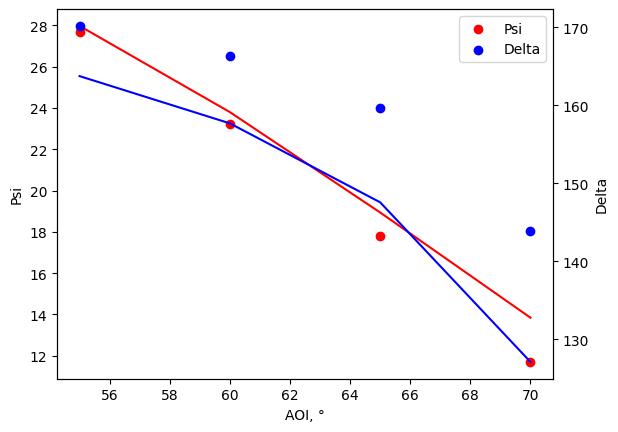

In [ ]:
fig, ax = plt.subplots()
axt = ax.twinx()

aois = np.linspace(50, 75, 100)

for dat in data.unique_wavelength_data():
    wavelength, aois, psi_d, delta_d = dat # from the raw data file; symbols on graph
    wavelength_aois = np.c_[np.ones_like(aois) * wavelength, aois]

    psi, delta = model(wavelength_aois)
    ax.plot(aois, psi, color="r") # lines are from "model" we just constructed
    p = ax.scatter(data.aoi, data.psi, color="r") # symbols from data

    axt.plot(aois, delta, color="b") # lines from model
    d = axt.scatter(data.aoi, data.delta,color="b") # symbols from data

ax.legend(handles=[p, d], labels=["Psi", "Delta"])
ax.set(ylabel="Psi", xlabel="AOI, °")
axt.set(ylabel="Delta")
plt.show()

## Combine the model with the function
This will essentially just wrap the model with the data, so that this singular object can be optimized.

Below, this combines the two so that the model and data become "linked" and become something that we try to match to one another

In [ ]:
objective = ObjectiveSE(model,data) # defining some objective function that quantifies a match
# between the model we've made and the real data

In [ ]:
objective

Objective(ReflectModel(Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=100.0, ub=500.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=20.0, name=' - thick', vary=True, bounds=Interval(lb=1.0, ub=30.0), constraint=None), 

## Finally, fit the data.

In [ ]:
fitter = CurveFitter(objective) # the objective integrated the model and the data
fitter.fit(method="least_squares")

     message: `xtol` termination condition is satisfied.
     success: True
      status: 3
         fun: [ 8.311e-02  1.380e-01  2.394e-01  5.105e-02  1.800e-01
                1.402e-01  8.344e-02  1.903e-01]
           x: [ 1.323e+02  1.000e+00]
        cost: 0.09055641524849325
         jac: [[ 1.659e-03  1.675e-03]
               [ 3.638e-03  3.620e-03]
               ...
               [ 1.450e-01  1.415e-01]
               [-2.257e-01 -2.202e-01]]
        grad: [ 2.397e-09  6.123e-05]
  optimality: 7.750069914670909e-08
 active_mask: [ 0 -1]
        nfev: 11
        njev: 10
       covar: [[ 9.652e+05 -9.891e+05]
               [-9.891e+05  1.014e+06]]
      stderr: [ 9.825e+02  1.007e+03]

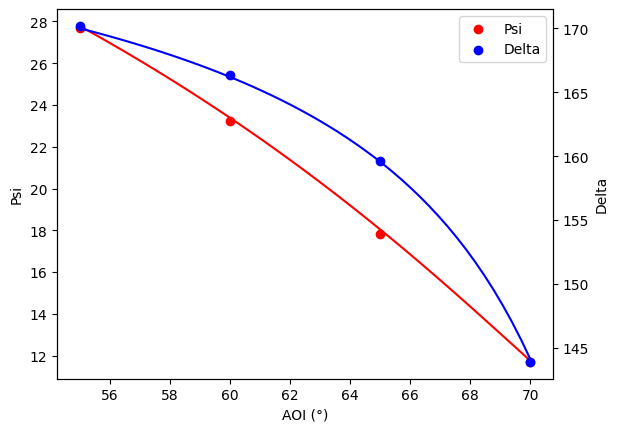

In [ ]:
fig, ax = objective.plot() # objective stores fit parameters (e.g. thickness) and data,
# and the objective assesses fit between data simulated from the fit parameters and the real data

In [ ]:
objective.model

ReflectModel(Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=132.33887932161053, name=' - thick', vary=True, bounds=Interval(lb=100.0, ub=500.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=1.000000000000031, name=' - thick', vary=True, bounds=Interval(lb=1.0, ub=30.0), co

In [ ]:
for i, x in enumerate(objective.model.parameters): # now we have the optimized version of the model
    print(x)

________________________________________________________________________________
Parameters: 'instrument parameters'
<Parameter:'delta offset' , value=0  (fixed) , bounds=[-inf, inf]>
________________________________________________________________________________
Parameters: 'Structure - ' 
________________________________________________________________________________
Parameters:       ''       
<Parameter:  ' - thick'   , value=0  (fixed) , bounds=[-inf, inf]>
<Parameter:  ' - rough'   , value=0  (fixed) , bounds=[-inf, inf]>
<Parameter:' - volfrac solvent', value=0  (fixed) , bounds=[0.0, 1.0]>
________________________________________________________________________________
Parameters:    'PNIPAM'    
<Parameter:  ' - thick'   , value=132.339  +/- 982 , bounds=[100.0, 500.0]>
<Parameter: ' - cauchy A' , value=1.47  (fixed) , bounds=[-inf, inf]>
<Parameter: ' - cauchy B' , value=0.00495  (fixed) , bounds=[-inf, inf]>
<Parameter: ' - cauchy C' , value=0  (fixed) , bounds=[-inf, inf]

## Re-doing in light of large error ranges (see recording for explanation)  
I have copy-pasted everything from above. I will highlight the changes I make in <font color='magenta'>magenta font.

## Make "slabs" of the films we will need to model this.

When we have a film on top of a silicon substrate, there will typically be an oxide layer of SiO2 in between. On commercial wafers, this is generally assumed to be around 2 nm unless otherwise stated.

Silicon has no layer thickness; reflective substrate (no need to build a layer to fit)

Initialize starting guesses for the thicknesses of the two layers which we want to find the thickness of. <font color='red'>Note that units here are in $Å$.

In [ ]:
silica_layer = sio2(22) # initialize using the material variables we defined earlier
polymer_layer = PNIPAM(200)
# initiate specific layers for this stack using the general materials we defined above
# first guess for polymer layer is 20 nm

Next, we will turn on what parameters we want to fit for. Here, we have dry films, so vfsolv (volume fraction solvent) is set to 0. Roughness is also set to 0, though we haven't explicitly named it. The only thing we are fitting in these films is the thickness. Even though we are only trying to find the thickness of the PNIPAM, there can be small variations in actual oxide thickness, so we need to fit that as well.

<font color='magenta'>In the original sample, I let the silica thickness vary down to 1 angstrom, which is physically much smaller than we know silica thicknesses are (they're always at least 2 nm thick)

In [ ]:
# setting upper and lower bounds for how much we can change our guess
silica_layer.name = "Silica"
# NEXT LINE IS WHAT I CHANGED
silica_layer.thick.setp(vary=True, bounds=(0, 50)) # letting the thickness vary
silica_layer.vfsolv.setp(vary=False, value=0) # keeping the volume fraction of solvent at 0

polymer_layer.name = "PNIPAM"
polymer_layer.thick.setp(vary=True, bounds=(50, 250)) # looking at a wider range of thicknesses
polymer_layer.vfsolv.setp(vary=False, value=0)

In [ ]:
polymer_layer

SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=50.0, ub=250.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None)

Above, note that we set "vary=True" for the thicknesses of both, and then we specify upper bounds. For the SiO2, we are saying that it can hold possible values from 0.1 nm up to 3 nm, while the PNIPAM can be anywhere from 10 to 50 nm. This will require some prior knowledge of your system to set realistic bounds.

## Assemble the component slabs into a "structure"  
The | characters used in constructing the structure are interesting to me. I believe they are specific to this package, as I have never seen them used in any other code. The materials/slabs move top to bottom. Note that air is a continuous medium, so it doesn't have a thickness; Silicon is the substrate, and it is reflective, so it doesn't need a thickness either.

In [ ]:
structure = air() | polymer_layer | silica_layer | si()

In [ ]:
structure

Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=50.0, ub=250.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=22.0, name=' - thick', vary=True, bounds=Interval(lb=0.0, ub=50.0), constraint=None), <refellips.dispersion.RI

## Make a model
This step may seem redundant, but it transforms the structure into an object that, code-wise, can be used for further fitting.

In [ ]:
model = ReflectModelSE(structure)

In [ ]:
model

ReflectModel(Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=50.0, ub=250.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=22.0, name=' - thick', vary=True, bounds=Interval(lb=0.0, ub=50.0), constraint=None), <refellips.

"Delta offset" is an instrumental error parameter. This would be a constant value for your particular instrument. It would ideally be found by running a control sample first, such as a bare piece of silicon, and then be fixed in your model. Here it is set to 0 and fixed.

In [ ]:
model.delta_offset.setp(value=0, vary=False) # this means the instrument is working as expected

Let's see what we have before we perform the fitting. The individual symbols are the experimental values for psi and delta; the lines (which have 4 points) are what the simulated psi and delta would look like at the currently-specified film parameters.

In [ ]:
data # from the filepath

Data1D(data='/content/refellips/demos/testData1_11nm_PNIPAM_on_Si_EP4.dat', mask=None)

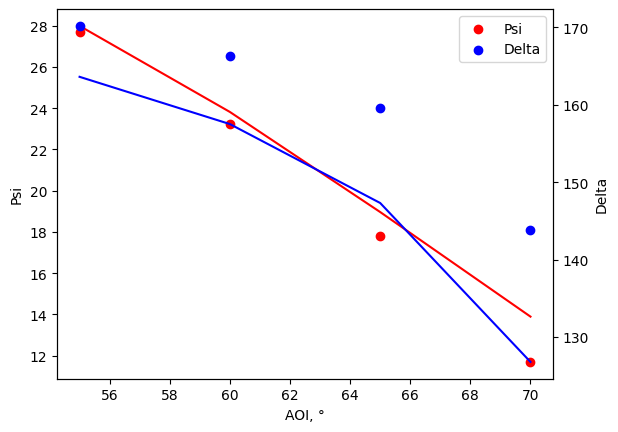

In [ ]:
fig, ax = plt.subplots()
axt = ax.twinx()

aois = np.linspace(50, 75, 100)

for dat in data.unique_wavelength_data():
    wavelength, aois, psi_d, delta_d = dat # from the raw data file; symbols on graph
    wavelength_aois = np.c_[np.ones_like(aois) * wavelength, aois]

    psi, delta = model(wavelength_aois)
    ax.plot(aois, psi, color="r") # lines are from "model" we just constructed
    p = ax.scatter(data.aoi, data.psi, color="r") # symbols from data

    axt.plot(aois, delta, color="b") # lines from model
    d = axt.scatter(data.aoi, data.delta,color="b") # symbols from data

ax.legend(handles=[p, d], labels=["Psi", "Delta"])
ax.set(ylabel="Psi", xlabel="AOI, °")
axt.set(ylabel="Delta")
plt.show()

## Combine the model with the function
This will essentially just wrap the model with the data, so that this singular object can be optimized.

Below, this combines the two so that the model and data become "linked" and become something that we try to match to one another

In [ ]:
objective = ObjectiveSE(model,data) # defining some objective function that quantifies a match
# between the model we've made and the real data

In [ ]:
objective

Objective(ReflectModel(Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=200.0, name=' - thick', vary=True, bounds=Interval(lb=50.0, ub=250.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=22.0, name=' - thick', vary=True, bounds=Interval(lb=0.0, ub=50.0), constraint=None), <

## Finally, fit the data.

In [ ]:
fitter = CurveFitter(objective) # the objective integrated the model and the data
fitter.fit(method="least_squares")

LinAlgError: The following Parameters have no effect on Objective.residuals, please consider fixing them.
[Parameter(value=1.5146129380243427e-28, name=' - thick', vary=True, bounds=Interval(lb=0.0, ub=50.0), constraint=None)]

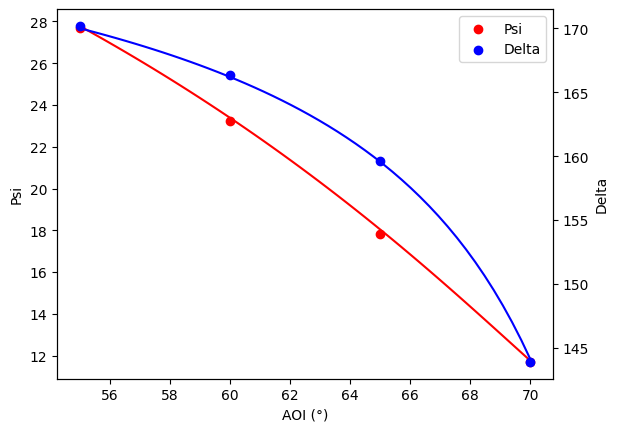

In [ ]:
fig, ax = objective.plot() # objective stores fit parameters (e.g. thickness) and data,
# and the objective assesses fit between data simulated from the fit parameters and the real data

In [ ]:
objective.model

ReflectModel(Structure(components=[SlabSE(Parameter(value=0.0, name=' - thick', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), <refellips.dispersion.RI object at 0x791f5d4ab390>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=133.31473660461603, name=' - thick', vary=True, bounds=Interval(lb=50.0, ub=250.0), constraint=None), <refellips.dispersion.Cauchy object at 0x791f5a8779d0>, Parameter(value=0.0, name=' - rough', vary=False, bounds=Interval(lb=-np.inf, ub=np.inf), constraint=None), name='PNIPAM', vfsolv=Parameter(value=0.0, name=' - volfrac solvent', vary=False, bounds=Interval(lb=0.0, ub=1.0), constraint=None), interface=None), SlabSE(Parameter(value=1.5146129380243427e-28, name=' - thick', vary=True, bounds=Interval(lb=0.0, ub=50.0)

In [ ]:
for i, x in enumerate(objective.model.parameters): # now we have the optimized version of the model
    print(x)

________________________________________________________________________________
Parameters: 'instrument parameters'
<Parameter:'delta offset' , value=0  (fixed) , bounds=[-inf, inf]>
________________________________________________________________________________
Parameters: 'Structure - ' 
________________________________________________________________________________
Parameters:       ''       
<Parameter:  ' - thick'   , value=0  (fixed) , bounds=[-inf, inf]>
<Parameter:  ' - rough'   , value=0  (fixed) , bounds=[-inf, inf]>
<Parameter:' - volfrac solvent', value=0  (fixed) , bounds=[0.0, 1.0]>
________________________________________________________________________________
Parameters:    'PNIPAM'    
<Parameter:  ' - thick'   , value=133.315          , bounds=[50.0, 250.0]>
<Parameter: ' - cauchy A' , value=1.47  (fixed) , bounds=[-inf, inf]>
<Parameter: ' - cauchy B' , value=0.00495  (fixed) , bounds=[-inf, inf]>
<Parameter: ' - cauchy C' , value=0  (fixed) , bounds=[-inf, inf]>

<font size=4> What happened: There either was not actually an oxide on this Si substrate, or there was not enough fitting data to uniquely find its thickness. Instead, it just found a 13.3 nm-thick film on top of the Si. We will talk about this more in class. (I am not sure why I thought there was a 2 nm-thick oxide; perhaps this is because all of my own lab's Si wafers have 2 nm of oxide. I apologize for this.)